# C0 architecture comparison: DenseNet-121 vs ResNet-50 vs ViT-B/16

For each C0 backbone, the final C2 system was retrained with the same recipe (KNN CFs, K=10):
**Attr** = MLP I+C+D, **CNN** = dual_sal, **Ensemble** = Attr + CNN, all compared against the
threshold-adjusted **MSP**. Nothing was re-tuned per architecture.

Inputs:
- `C0_final*/multilabel_ignore/test_metrics.json`: C0 on the official CheXpert test set (n=202)
- `C2_arch_compare/summary.csv`, `deltas.csv`: from `code/c2_arch_compare.py` (patient bootstrap, 5,000 draws)

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = "/work3/s251710/thesis_results"
ARCHS = ["densenet121", "resnet50", "vit_b_16"]
ARCH_NAME = {"densenet121": "DenseNet-121", "resnet50": "ResNet-50", "vit_b_16": "ViT-B/16"}
DISEASES = ["effusion", "atelectasis", "cardiomegaly", "consolidation", "edema"]
C0_LABEL = {"effusion": "Pleural Effusion", "atelectasis": "Atelectasis",
            "cardiomegaly": "Cardiomegaly", "consolidation": "Consolidation", "edema": "Edema"}
C0_DIR = {"densenet121": "C0_final", "resnet50": "C0_final_resnet50", "vit_b_16": "C0_final_vit_b_16"}

COLORS = {"MSP": "#BFBFBF", "Attr": "#2863AB", "CNN": "#B02B27", "Ensemble": "#956ED2"}
pd.options.display.float_format = "{:.4f}".format

# Every figure is also written to FIG_DIR (PDF for \includegraphics, PNG raster copy),
# same convention as c0_analyse_predictions.ipynb.
FIG_DIR = os.path.abspath(os.path.join("figures", "c2"))
FIG_PREFIX = "c2_arch"
FIG_FORMATS = ("pdf", "png")


def save_fig(fig, name):
    """Write `fig` as FIG_DIR/<FIG_PREFIX>_<name>.<ext>."""
    os.makedirs(FIG_DIR, exist_ok=True)
    for ext in FIG_FORMATS:
        fig.savefig(os.path.join(FIG_DIR, f"{FIG_PREFIX}_{name}.{ext}"))

## 1. C0 performance per architecture

AUROC of each C0 per disease, measured two ways:
- **test set**: the official CheXpert test split (only 202 images, so noisy)
- **C2 set**: the rows the C2 models are trained/evaluated on (~80-95k images per disease)

In [2]:
rows = []
for arch in ARCHS:
    path = os.path.join(RESULTS, C0_DIR[arch], "multilabel_ignore", "test_metrics.json")
    metrics = json.load(open(path))
    for d in DISEASES:
        rows.append({"arch": arch, "disease": d,
                     "test AUROC": metrics["test_auc_per_label"][C0_LABEL[d]]})
c0_test = pd.DataFrame(rows)

summary = pd.read_csv(os.path.join(RESULTS, "C2_arch_compare", "summary.csv"))
c0 = c0_test.merge(summary[["arch", "disease", "n", "C0 AUROC", "C0 accuracy"]],
                   on=["arch", "disease"])
c0 = c0.rename(columns={"C0 AUROC": "C2-set AUROC", "C0 accuracy": "C2-set accuracy"})

c0_table = c0.pivot(index="disease", columns="arch", values="C2-set AUROC").loc[DISEASES, ARCHS]
c0_table.loc["MEAN"] = c0_table.mean()
print("C0 AUROC on the C2 set")
display(c0_table)

c0_test_table = c0.pivot(index="disease", columns="arch", values="test AUROC").loc[DISEASES, ARCHS]
c0_test_table.loc["MEAN"] = c0_test_table.mean()
print("C0 AUROC on the CheXpert test set (n=202)")
display(c0_test_table)

acc_table = c0.pivot(index="disease", columns="arch", values="C2-set accuracy").loc[DISEASES, ARCHS]
print("C0 accuracy on the C2 set (= share of 'correct' labels for C2)")
display(acc_table)

C0 AUROC on the C2 set


arch,densenet121,resnet50,vit_b_16
disease,,,
effusion,0.8842,0.8744,0.8851
atelectasis,0.7151,0.7076,0.7227
cardiomegaly,0.8670,0.8653,0.8674
consolidation,0.7358,0.7280,0.7500
edema,0.8469,0.8460,0.8521
MEAN,0.8098,0.8043,0.8155


C0 AUROC on the CheXpert test set (n=202)


arch,densenet121,resnet50,vit_b_16
disease,,,
effusion,0.9091,0.9257,0.9274
atelectasis,0.7561,0.7452,0.7764
cardiomegaly,0.7792,0.8424,0.7916
consolidation,0.8844,0.8989,0.8985
edema,0.9232,0.9169,0.9098
MEAN,0.8504,0.8658,0.8608


C0 accuracy on the C2 set (= share of 'correct' labels for C2)


arch,densenet121,resnet50,vit_b_16
disease,,,
effusion,0.7944,0.7877,0.8009
atelectasis,0.5946,0.5890,0.6025
cardiomegaly,0.8103,0.8258,0.8252
consolidation,0.6113,0.6242,0.6189
edema,0.7483,0.7393,0.7554


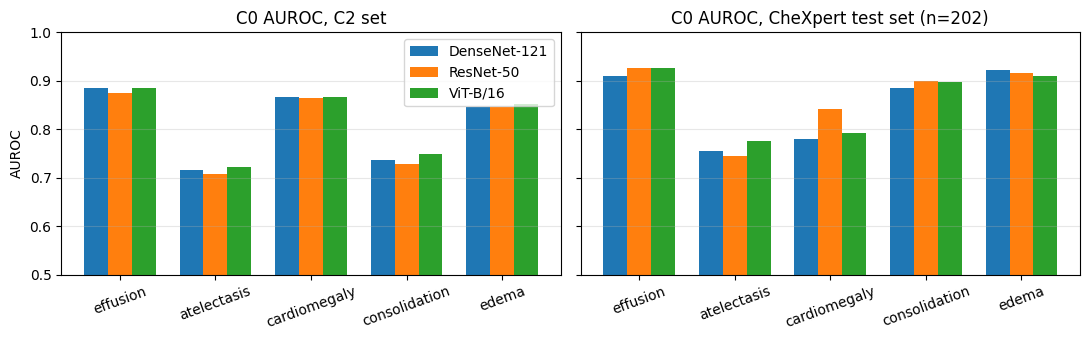

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
width = 0.25
x = np.arange(len(DISEASES))
for ax, table, title in [(axes[0], c0_table, "C0 AUROC, C2 set"),
                         (axes[1], c0_test_table, "C0 AUROC, CheXpert test set (n=202)")]:
    for i, arch in enumerate(ARCHS):
        ax.bar(x + (i - 1) * width, table.loc[DISEASES, arch], width, label=ARCH_NAME[arch])
    ax.set_xticks(x)
    ax.set_xticklabels(DISEASES, rotation=20)
    ax.set_title(title)
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("AUROC")
axes[0].legend()
plt.tight_layout()
save_fig(fig, "c0_auroc")
plt.show()

## 2. C2 failure prediction per architecture
Mean-fold AUROC of predicting C0 correctness (higher is better), with 95% bootstrap intervals.

In [4]:
METHODS = ["MSP", "Attr", "CNN", "Ensemble"]

c2 = summary[["arch", "disease"] + [f"AUROC {m}" for m in METHODS]].copy()
c2.columns = ["arch", "disease"] + METHODS

for arch in ARCHS:
    table = c2[c2.arch == arch].set_index("disease").loc[DISEASES, METHODS]
    table.loc["MEAN"] = table.mean()
    print(ARCH_NAME[arch])
    display(table)

DenseNet-121


,MSP,Attr,CNN,Ensemble
disease,,,,
effusion,0.7817,0.7826,0.7776,0.7874
atelectasis,0.8633,0.8617,0.8562,0.8626
cardiomegaly,0.9168,0.9188,0.9163,0.9206
consolidation,0.9462,0.9447,0.9424,0.9455
edema,0.8303,0.8344,0.8314,0.8372
MEAN,0.8677,0.8684,0.8648,0.8707


ResNet-50


,MSP,Attr,CNN,Ensemble
disease,,,,
effusion,0.7693,0.7836,0.7792,0.7904
atelectasis,0.8608,0.8612,0.8566,0.8630
cardiomegaly,0.9095,0.9095,0.9071,0.9115
consolidation,0.9453,0.9447,0.9422,0.9452
edema,0.8356,0.8394,0.8324,0.8408
MEAN,0.8641,0.8677,0.8635,0.8702


ViT-B/16


,MSP,Attr,CNN,Ensemble
disease,,,,
effusion,0.7732,0.7692,0.7557,0.7769
atelectasis,0.8653,0.8623,0.8457,0.8625
cardiomegaly,0.9108,0.9116,0.9046,0.9132
consolidation,0.9476,0.9445,0.9370,0.9430
edema,0.8320,0.8296,0.8146,0.8314
MEAN,0.8658,0.8635,0.8515,0.8654


In [5]:
# Plot style shared with C2_evaluation.ipynb: points + 95% bootstrap whiskers, one panel per
# disease with its own y range, MSP as a dashed grey line. Each method is offset within its arch.
import sys
sys.path.insert(0, "code")
import thesis_style as TS
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter, MaxNLocator

POINT_COLORS = {"Attr": TS.FAMILY["attr"], "CNN": TS.FAMILY["cnn"], "Ensemble": TS.ENS}
OFFSET = {"Attr": -0.22, "CNN": 0.0, "Ensemble": 0.22}
PANELS = DISEASES + ["AVERAGE"]

# Same sizes as the points panels in C2_evaluation.ipynb: 50 x 54 mm per cell (3 columns ->
# 150 mm, printed at its true size), square plotting area, s=38 points with a coloured edge.
PANEL = (50 * TS.MM, 54 * TS.MM)
POINT_S, POINT_EDGE = 38, 0.9
# Two-line tick labels: three one-line names do not fit under a 50 mm panel.
ARCH_TICK = {"densenet121": "DenseNet\n121", "resnet50": "ResNet\n50", "vit_b_16": "ViT\nB/16"}


def round_ticks(ax):
    """3-4 y-ticks on a round step (1, 2 or 5 x 10^n), as in C2_evaluation.ipynb."""
    loc = MaxNLocator(nbins=4, steps=[1, 2, 5, 10])
    ax.yaxis.set_major_locator(loc)
    t = loc.tick_values(*ax.get_ylim())
    step = (t[1] - t[0]) if len(t) > 1 else 0.01
    ax.yaxis.set_major_formatter(FormatStrFormatter(f"%.{max(2, int(np.ceil(-np.log10(step) - 1e-9)))}f"))


def arch_axes(ax, d):
    """Separators between archs, arch tick labels, panel title, square box."""
    for j in range(1, len(ARCHS)):
        ax.axvline(j - 0.5, color=TS.HAIR, lw=TS.LW["axis"], zorder=0)
    ax.set_xticks(range(len(ARCHS)), [ARCH_TICK[a] for a in ARCHS])
    ax.set_xlim(-0.5, len(ARCHS) - 0.5)
    ax.set_title(f"average of {len(DISEASES)} diseases" if d == "AVERAGE" else d)
    round_ticks(ax)
    ax.set_box_aspect(1)


def draw_point(ax, x, y, lo, hi, m):
    ax.errorbar(x, y, yerr=[[y - lo], [hi - y]], fmt="none", ecolor=TS.INK,
                elinewidth=TS.LW["ref"], capsize=0, zorder=2)
    ax.scatter(x, y, s=POINT_S, color=POINT_COLORS[m], edgecolor=POINT_COLORS[m],
               linewidth=POINT_EDGE, zorder=3)


def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def point_legend(fig, msp_label):
    handles = [Line2D([], [], ls="none", marker="o", markersize=5.5, color=POINT_COLORS[m],
                      markeredgecolor=POINT_COLORS[m], label=m) for m in POINT_COLORS]
    handles.append(Line2D([], [], color=TS.GREY, ls="--", lw=TS.LW["ref"], label=msp_label))
    handles.append(Line2D([], [], color=TS.INK, lw=TS.LW["ref"], label="95% bootstrap interval"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.01))


# 95% interval of each method's AUROC: per disease from summary.csv; for the average over
# diseases, average the 5 diseases inside each bootstrap draw, then take percentiles.
reps = pd.read_csv(os.path.join(RESULTS, "C2_arch_compare", "replicates.csv"), index_col="replicate")


def auroc_point(arch, panel, method):
    if panel != "AVERAGE":
        r = summary[(summary.arch == arch) & (summary.disease == panel)].iloc[0]
        return r[f"AUROC {method}"], r[f"AUROC {method} lo"], r[f"AUROC {method} hi"]
    point = summary[summary.arch == arch][f"AUROC {method}"].mean()
    draws = np.mean([reps[f"AUROC|{arch}|{d}|{method}"] for d in DISEASES], axis=0)
    return point, np.percentile(draws, 2.5), np.percentile(draws, 97.5)

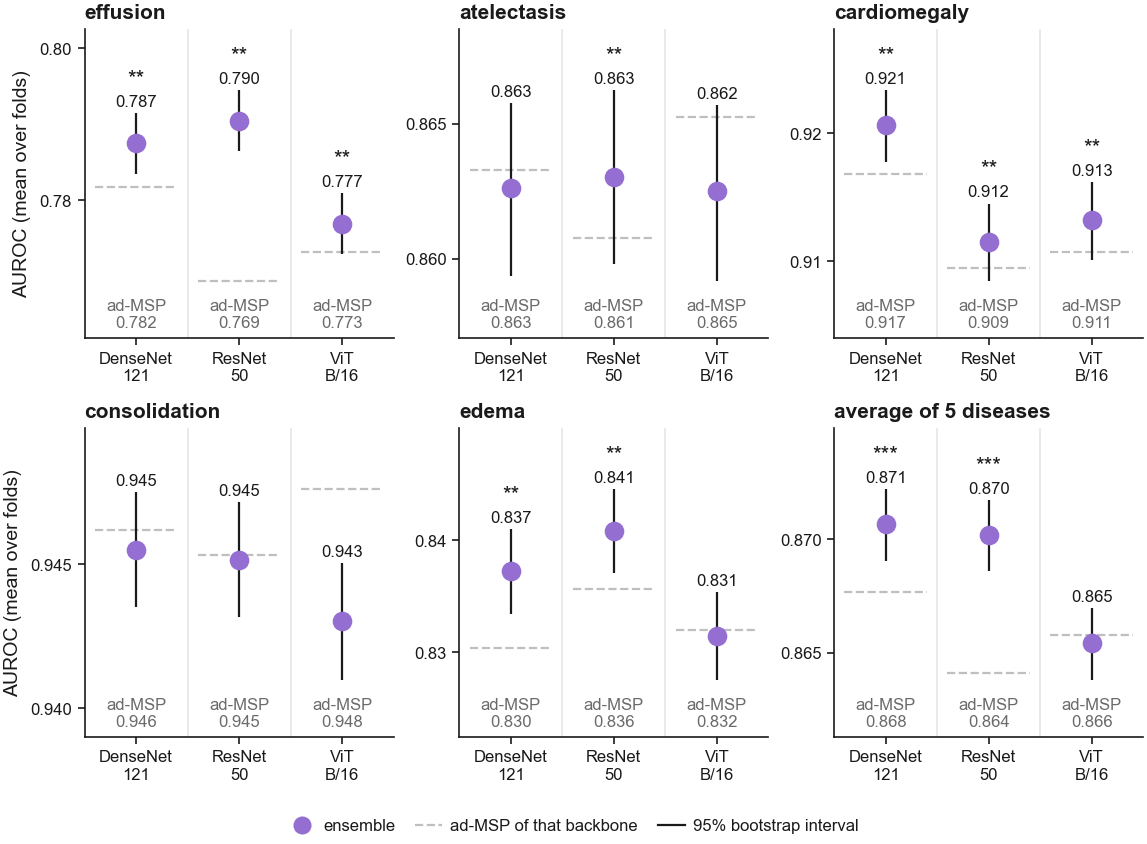

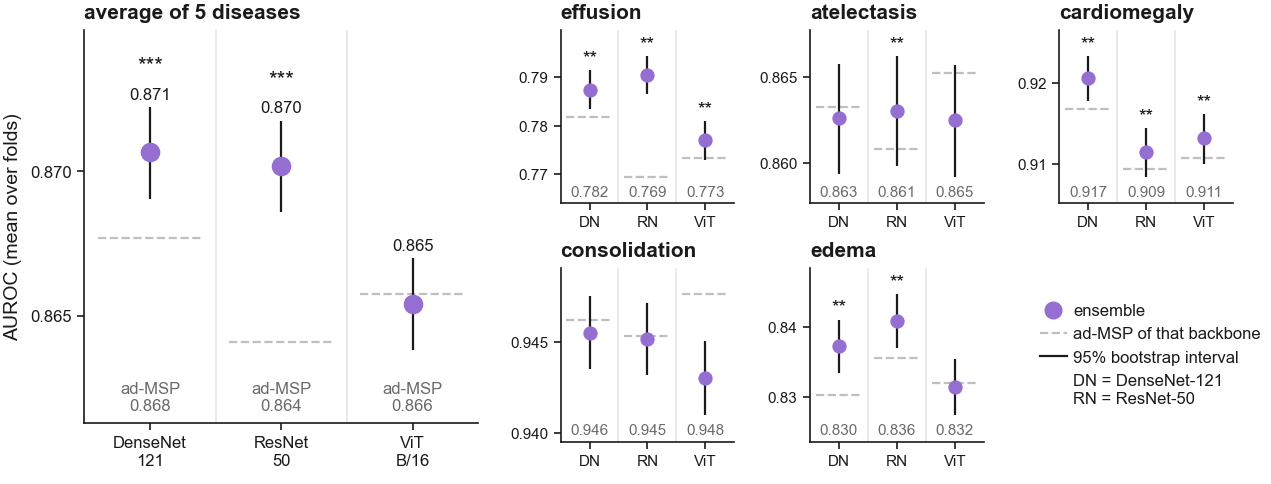

In [6]:
# Final system only: one ensemble point per backbone, drawn like aim2b_ensemble_points in
# C2_evaluation.ipynb (value above the whisker, stars, MSP note at the bottom). Each backbone
# has its own C0 and so its own adjusted MSP: a dashed segment across that backbone's column,
# its value written at the foot of the column. Stars: Ensemble - that backbone's adjusted MSP,
# Holm across the 5 diseases within the backbone (the average is a single test).
ENS_P = (pd.read_csv(os.path.join(RESULTS, "C2_arch_compare", "deltas.csv"))
         .query("metric == 'AUROC' and comparison == 'Ensemble - MSP'")
         .set_index(["arch", "disease"]).p_adj)
# Small side panels of the key figure: one-line backbone names, as two-line ones collide
ARCH_TICK_SMALL = {"densenet121": "DN", "resnet50": "RN", "vit_b_16": "ViT"}


def ens_panel(ax, d, compact=False):
    """`compact` is a small side panel of the key figure (as points_panel in
    C2_evaluation.ipynb): no values, smaller points and stars, MSP value only, short ticks."""
    pts = np.array([auroc_point(a, d, "Ensemble") for a in ARCHS])   # (y, lo, hi) per arch
    msp = np.array([auroc_point(a, d, "MSP")[0] for a in ARCHS])
    lo, top = min(pts[:, 1].min(), msp.min()), max(pts[:, 2].max(), msp.max())
    span = max(top - lo, 1e-4)
    # Room below for the MSP note, above for the value and the stars
    ax.set_ylim(lo - span * (0.22 if compact else 0.30), top + span * (0.22 if compact else 0.32))
    x = np.arange(len(ARCHS))
    ax.errorbar(x, pts[:, 0], yerr=[pts[:, 0] - pts[:, 1], pts[:, 2] - pts[:, 0]], fmt="none",
                ecolor=TS.INK, elinewidth=TS.LW["ref"], capsize=0, zorder=3)
    ax.scatter(x, pts[:, 0], s=18 if compact else POINT_S, c=[TS.ENS], edgecolors=[TS.ENS],
               linewidths=POINT_EDGE, zorder=4)
    for j, arch in enumerate(ARCHS):
        y, _, hi = pts[j]
        ax.hlines(msp[j], j - 0.4, j + 0.4, color=TS.GREY, ls="--", lw=TS.LW["ref"], zorder=1)
        if not compact:
            # White backing: the MSP segment often runs through this height
            ax.text(j, hi + span * 0.02, f"{y:.3f}", ha="center", va="bottom",
                    fontsize=TS.FS["small"], color=TS.INK, zorder=4,
                    bbox=dict(fc="white", ec="none", pad=0.4, alpha=0.85))
        p = ENS_P[(arch, d)]
        if y > msp[j] and p < 0.05:      # stars only for a significant gain over MSP
            ax.text(j, hi + span * (0.02 if compact else 0.13), stars(p), ha="center",
                    va="bottom", fontsize=TS.FS["base"] if compact else TS.FS["head"],
                    color=TS.INK, zorder=4)
        ax.text(j, 0.025, f"{msp[j]:.3f}" if compact else f"ad-MSP\n{msp[j]:.3f}",
                transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontsize=TS.FS["tiny"] if compact else TS.FS["small"], color=TS.MUTED)
    arch_axes(ax, d)
    if compact:
        ax.set_xticks(range(len(ARCHS)), [ARCH_TICK_SMALL[a] for a in ARCHS])
        round_ticks(ax)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3, steps=[1, 2, 5, 10]))
        ax.tick_params(labelsize=TS.FS["tiny"])


ENS_LEGEND = [Line2D([], [], ls="none", marker="o", markersize=5.5, color=TS.ENS,
                     markeredgecolor=TS.ENS, label="ensemble"),
              Line2D([], [], color=TS.GREY, ls="--", lw=TS.LW["ref"],
                     label="ad-MSP of that backbone"),
              Line2D([], [], color=TS.INK, lw=TS.LW["ref"], label="95% bootstrap interval")]

with plt.rc_context():
    TS.apply()
    fig, axes = plt.subplots(2, 3, figsize=(3 * PANEL[0], 2 * PANEL[1]))
    for ax, d in zip(axes.ravel(), PANELS):
        ens_panel(ax, d)
    for ax in axes[:, 0]:
        ax.set_ylabel("AUROC (mean over folds)")
    fig.legend(handles=ENS_LEGEND, loc="lower center", ncol=len(ENS_LEGEND),
               bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.04, 1, 1), w_pad=0.6, h_pad=1.2)
    save_fig(fig, "auroc")
    plt.show()

# Key-figure version (as the C2_evaluation key figures): the average large on the left, the
# diseases as small multiples beside it, legend in the empty cell. PDF + PNG, in figures/c2_key.
with plt.rc_context():
    TS.apply()
    key_legend = ENS_LEGEND + [Line2D([], [], ls="none", label="DN = DenseNet-121\nRN = ResNet-50")]
    fig = TS.key_figure(PANELS, ens_panel, key_legend)
    os.makedirs(os.path.join("figures", "c2_key"), exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join("figures", "c2_key", f"{FIG_PREFIX}_auroc.{ext}"))
    plt.show()

## 3. Gain over MSP
AUROC gain of each method over MSP, 95% interval, and Holm-adjusted p-value (across the 5 diseases
within each architecture). `AVERAGE` is the mean over diseases.

In [7]:
deltas = pd.read_csv(os.path.join(RESULTS, "C2_arch_compare", "deltas.csv"))
auroc = deltas[deltas.metric == "AUROC"]

for arch in ARCHS:
    print(ARCH_NAME[arch])
    show = auroc[auroc.arch == arch][["comparison", "disease", "gain", "lo", "hi", "p_adj"]]
    display(show.pivot(index="disease", columns="comparison", values="gain")
            .loc[DISEASES + ["AVERAGE"], ["Ensemble - MSP", "Attr - MSP", "CNN - MSP"]])

DenseNet-121


comparison,Ensemble - MSP,Attr - MSP,CNN - MSP
disease,,,
effusion,0.0057,0.0008,-0.0041
atelectasis,-0.0007,-0.0016,-0.0071
cardiomegaly,0.0038,0.0020,-0.0006
consolidation,-0.0007,-0.0015,-0.0038
edema,0.0069,0.0041,0.0011
AVERAGE,0.0030,0.0008,-0.0029


ResNet-50


comparison,Ensemble - MSP,Attr - MSP,CNN - MSP
disease,,,
effusion,0.0211,0.0143,0.0098
atelectasis,0.0023,0.0005,-0.0042
cardiomegaly,0.0020,-0.0000,-0.0024
consolidation,-0.0001,-0.0006,-0.0031
edema,0.0052,0.0038,-0.0032
AVERAGE,0.0061,0.0036,-0.0006


ViT-B/16


comparison,Ensemble - MSP,Attr - MSP,CNN - MSP
disease,,,
effusion,0.0037,-0.0039,-0.0175
atelectasis,-0.0028,-0.0030,-0.0195
cardiomegaly,0.0024,0.0009,-0.0062
consolidation,-0.0046,-0.0031,-0.0107
edema,-0.0006,-0.0024,-0.0174
AVERAGE,-0.0004,-0.0023,-0.0142


In [8]:
# Full table with intervals and p-values for the final system only
ens = auroc[auroc.comparison == "Ensemble - MSP"].copy()
ens["significant"] = (ens.gain > 0) & (ens.p_adj < 0.05)
ens["arch"] = ens.arch.map(ARCH_NAME)
display(ens[["arch", "disease", "MSP", "Ensemble", "gain", "lo", "hi", "p_adj", "significant"]]
        .reset_index(drop=True))

,arch,disease,MSP,Ensemble,gain,lo,hi,p_adj,significant
0,DenseNet-121,effusion,0.7817,0.7874,0.0057,0.0042,0.0072,0.0010,True
1,DenseNet-121,atelectasis,0.8633,0.8626,-0.0007,-0.0020,0.0006,0.3060,False
2,DenseNet-121,cardiomegaly,0.9168,0.9206,0.0038,0.0028,0.0047,0.0010,True
3,DenseNet-121,consolidation,0.9462,0.9455,-0.0007,-0.0016,0.0002,0.2864,False
4,DenseNet-121,edema,0.8303,0.8372,0.0069,0.0057,0.0081,0.0010,True
5,DenseNet-121,AVERAGE,0.8677,0.8707,0.0030,0.0025,0.0035,0.0002,True
6,ViT-B/16,effusion,0.7732,0.7769,0.0037,0.0020,0.0054,0.0010,True
7,ViT-B/16,atelectasis,0.8653,0.8625,-0.0028,-0.0039,-0.0016,0.0010,False
8,ViT-B/16,cardiomegaly,0.9108,0.9132,0.0024,0.0015,0.0034,0.0010,True
9,ViT-B/16,consolidation,0.9476,0.9430,-0.0046,-0.0055,-0.0036,0.0010,False


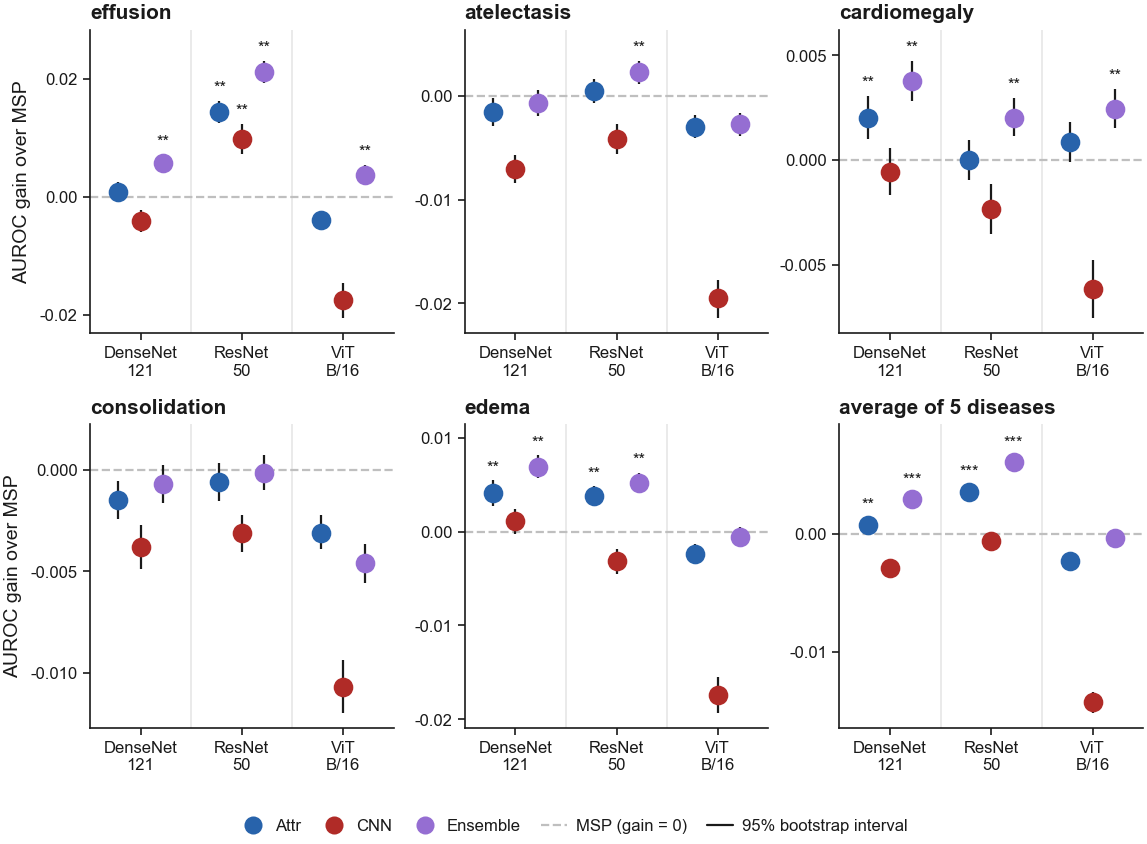

In [9]:
# Gain over each arch's own MSP (0 = MSP), 95% paired bootstrap interval, Holm stars
COMPS = {"Attr": "Attr - MSP", "CNN": "CNN - MSP", "Ensemble": "Ensemble - MSP"}

with plt.rc_context():
    TS.apply()
    fig, axes = plt.subplots(2, 3, figsize=(3 * PANEL[0], 2 * PANEL[1]))
    for ax, d in zip(axes.ravel(), PANELS):
        sub = auroc[auroc.disease == d]
        span = sub.hi.max() - sub.lo.min()
        ax.axhline(0, color=TS.GREY, ls="--", lw=TS.LW["ref"], zorder=1)
        for j, arch in enumerate(ARCHS):
            for m, comp in COMPS.items():
                r = sub[(sub.arch == arch) & (sub.comparison == comp)].iloc[0]
                x = j + OFFSET[m]
                draw_point(ax, x, r.gain, r.lo, r.hi, m)
                if r.gain > 0:      # stars only for a significant improvement over MSP
                    ax.text(x, r.hi + 0.02 * span, stars(r.p_adj), ha="center", va="bottom",
                            fontsize=TS.FS["small"], color=TS.INK)
        ax.set_ylim(min(sub.lo.min(), 0) - 0.06 * span, max(sub.hi.max(), 0) + 0.12 * span)
        arch_axes(ax, d)
    for ax in axes[:, 0]:
        ax.set_ylabel("AUROC gain over MSP")
    point_legend(fig, "MSP (gain = 0)")
    fig.tight_layout(rect=(0, 0.05, 1, 1), w_pad=0.6, h_pad=1.2)
    save_fig(fig, "gain_over_msp")
    plt.show()


## 3b. Final system vs adjusted MSP, per architecture

AUROC gain of the final ensemble over **its own backbone's adjusted MSP** (threshold MSP at that
C0's Youden threshold), as a paired difference: `AUROC(ensemble) - AUROC(adjusted MSP)` on the same
bootstrap draws. One panel per disease plus the average, x = backbone, **one y axis shared by all
panels** so magnitudes compare across diseases. The dashed zero line is each backbone's own MSP,
so the baseline differs per backbone.

Whiskers are the **paired** 95% bootstrap interval of the difference (5,000 patient-level draws,
`c2_arch_compare.py`), so an interval crosses zero exactly when the result is not significant
(asserted in the cell). Filled + stars = Holm p < 0.05 across the five diseases within each
backbone (the average is a single test); open = not significant. Stars sit at the far end of the
whisker, so a loss has its stars below zero. `***` / `**` / `*` = p < 0.001 / 0.01 / 0.05; with
5,000 draws the per-disease ceiling after Holm is `**` (p floor 0.0002 x 5).

Suggested caption: *AUROC gain of the final C2 ensemble over the adjusted MSP, per C0 backbone.
Zero (dashed) is each backbone's own adjusted MSP (max-probability score at that C0's Youden
threshold), so the baseline differs per backbone; points below zero are losses. Whiskers: paired
95% patient-level bootstrap intervals of the difference (5,000 draws). Filled markers with stars are
significant after Holm correction across the five diseases within each backbone (the average is a
single test); \*\*\* p < 0.001, \*\* p < 0.01, \* p < 0.05; open markers are not significant.
All panels share the y axis.*

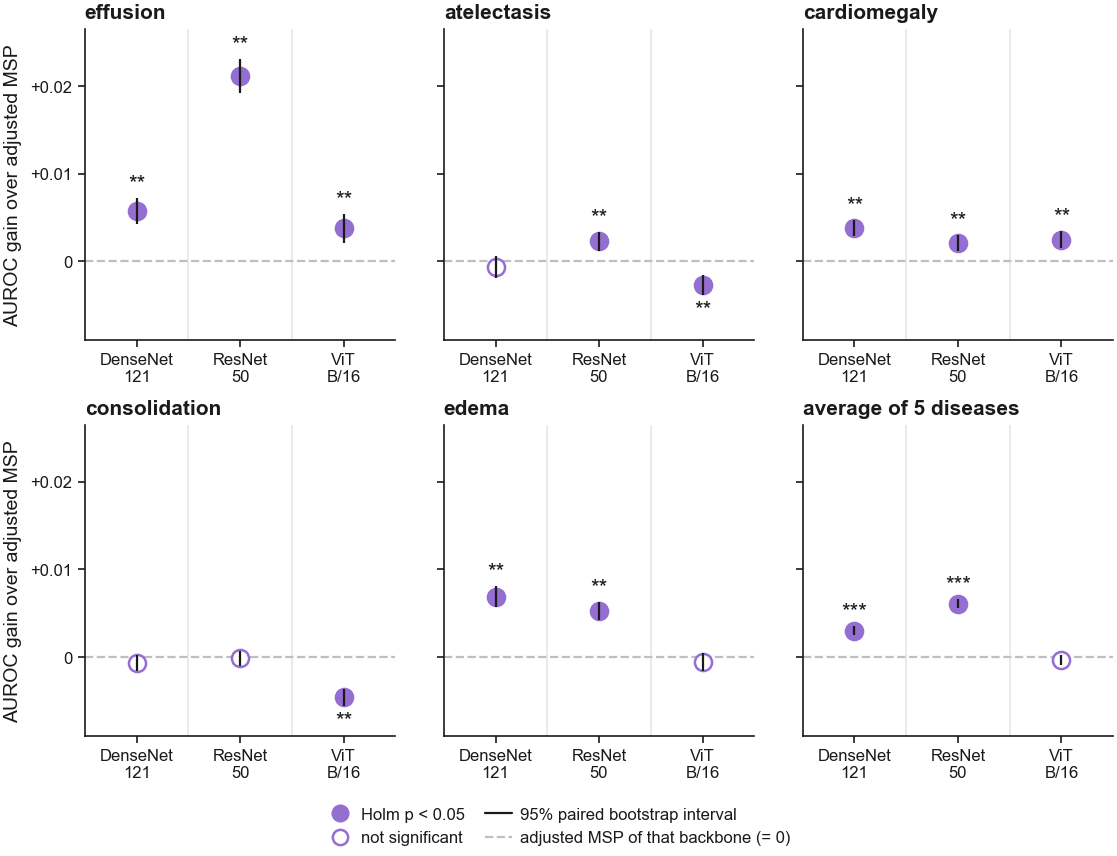

,,gain,lo,hi,p_adj
disease,arch,,,,
effusion,DenseNet-121,0.0057,0.0042,0.0072,0.0010
atelectasis,DenseNet-121,-0.0007,-0.0020,0.0006,0.3060
cardiomegaly,DenseNet-121,0.0038,0.0028,0.0047,0.0010
consolidation,DenseNet-121,-0.0007,-0.0016,0.0002,0.2864
edema,DenseNet-121,0.0069,0.0057,0.0081,0.0010
AVERAGE,DenseNet-121,0.0030,0.0025,0.0035,0.0002
effusion,ViT-B/16,0.0037,0.0020,0.0054,0.0010
atelectasis,ViT-B/16,-0.0028,-0.0039,-0.0016,0.0010
cardiomegaly,ViT-B/16,0.0024,0.0015,0.0034,0.0010


In [10]:
# Paired difference: ensemble - that backbone's adjusted MSP, with the PAIRED 95% bootstrap
# interval (deltas.csv lo/hi, the same draws as the test). Plotting the difference instead of
# absolute AUROC makes the interval and the star say the same thing (the interval excludes 0
# exactly when Holm p < 0.05, checked below), puts losses visibly below 0, and -- with one
# y axis shared by every panel -- makes magnitudes comparable across diseases.
ALPHA = 0.05
ENS_ROWS = deltas[(deltas.comparison == "Ensemble - MSP") & (deltas.metric == "AUROC")]

# Guard: a CI that excludes 0 with a non-significant Holm p (or vice versa) would bring the
# star/interval contradiction back -- stop rather than draw it.
_excl = (ENS_ROWS.lo > 0) | (ENS_ROWS.hi < 0)
assert (_excl == (ENS_ROWS.p_adj < ALPHA)).all(), ENS_ROWS[_excl != (ENS_ROWS.p_adj < ALPHA)]


def gain_panel(ax, d, ylim):
    ax.axhline(0, color=TS.GREY, ls="--", lw=TS.LW["ref"], zorder=1)
    span = ylim[1] - ylim[0]
    for j, arch in enumerate(ARCHS):
        r = ENS_ROWS[(ENS_ROWS.arch == arch) & (ENS_ROWS.disease == d)].iloc[0]
        sig = r.p_adj < ALPHA
        # Points-panel size (s=38, as aim2b_ensemble_points). Paired intervals are narrow, so
        # the thin whisker is drawn ON TOP of the dot -- an open point's interval stays visible
        # where it crosses zero.
        ax.scatter([j], [r.gain], s=POINT_S, c=[TS.ENS if sig else "white"], edgecolors=[TS.ENS],
                   linewidths=POINT_EDGE, zorder=2)
        ax.plot([j, j], [r.lo, r.hi], color=TS.INK, lw=TS.LW["ref"], solid_capstyle="butt",
                zorder=3)
        if sig:   # star on the far end of the whisker: above a gain, below a loss
            up = r.gain > 0
            ax.text(j, (r.hi if up else r.lo) + (1 if up else -1) * 0.015 * span, stars(r.p_adj),
                    ha="center", va="bottom" if up else "top", fontsize=TS.FS["head"],
                    color=TS.INK, zorder=4)
    for j in range(1, len(ARCHS)):
        ax.axvline(j - 0.5, color=TS.HAIR, lw=TS.LW["axis"], zorder=0)
    ax.set_xticks(range(len(ARCHS)), [ARCH_TICK[a] for a in ARCHS])
    ax.set_xlim(-0.5, len(ARCHS) - 0.5)
    ax.set_title(f"average of {len(DISEASES)} diseases" if d == "AVERAGE" else d)
    ax.set_box_aspect(1)


def ens_gain_figure():
    # One y range for all panels, from every interval plus room for the stars
    lo, hi = min(ENS_ROWS.lo.min(), 0), max(ENS_ROWS.hi.max(), 0)
    span = hi - lo
    ylim = (lo - 0.12 * span, hi + 0.12 * span)
    fig, axes = plt.subplots(2, 3, figsize=(3 * PANEL[0], 2 * PANEL[1]), sharey=True)
    for ax, d in zip(axes.ravel(), PANELS):
        ax.set_ylim(*ylim)
        gain_panel(ax, d, ylim)
    axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10]))
    axes[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(
        lambda y, _: "0" if abs(y) < 1e-12 else f"{y:+.2f}".replace("-", "−")))
    for ax in axes[:, 0]:
        ax.set_ylabel("AUROC gain over adjusted MSP")
    legend = [Line2D([], [], ls="none", marker="o", markersize=5.5, color=TS.ENS,
                     markeredgecolor=TS.ENS, label=f"Holm p < {ALPHA:g}"),
              Line2D([], [], ls="none", marker="o", markersize=5.5, mfc="white", mec=TS.ENS,
                     mew=POINT_EDGE, label="not significant"),
              Line2D([], [], color=TS.INK, lw=TS.LW["ref"], label="95% paired bootstrap interval"),
              TS.msp_handle("adjusted MSP of that backbone (= 0)")]
    fig.legend(handles=legend, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))
    fig.tight_layout(rect=(0, 0.07, 1, 1), w_pad=0.6, h_pad=2.2)
    return fig


with plt.rc_context():
    TS.apply()
    fig = ens_gain_figure()
    save_fig(fig, "ens_vs_msp")
    plt.show()

# The plotted numbers
show = ENS_ROWS[["arch", "disease", "gain", "lo", "hi", "p_adj"]].copy()
show["arch"] = show.arch.map(ARCH_NAME)
show.set_index(["disease", "arch"]).round(4)

## 4. Best architecture per component
For each disease, which C0 backbone gives the best attribute model, the best CNN and the best ensemble
(by C2 AUROC). Note the C0s differ, so the failure sets differ too: an arch can "win" simply because
its C0 errors are easier to predict. The gain over MSP (section 3) is the fairer comparison.

In [11]:
best_rows = []
for d in DISEASES:
    sub = c2[c2.disease == d].set_index("arch")
    row = {"disease": d}
    for m in METHODS:
        best_arch = sub[m].idxmax()
        row[f"best {m}"] = ARCH_NAME[best_arch]
        row[f"{m} AUROC"] = sub.loc[best_arch, m]
    best_rows.append(row)
best = pd.DataFrame(best_rows).set_index("disease")
display(best[["best Attr", "Attr AUROC", "best CNN", "CNN AUROC",
              "best Ensemble", "Ensemble AUROC", "best MSP", "MSP AUROC"]])

,best Attr,Attr AUROC,best CNN,CNN AUROC,best Ensemble,Ensemble AUROC,best MSP,MSP AUROC
disease,,,,,,,,
effusion,ResNet-50,0.7836,ResNet-50,0.7792,ResNet-50,0.7904,DenseNet-121,0.7817
atelectasis,ViT-B/16,0.8623,ResNet-50,0.8566,ResNet-50,0.8630,ViT-B/16,0.8653
cardiomegaly,DenseNet-121,0.9188,DenseNet-121,0.9163,DenseNet-121,0.9206,DenseNet-121,0.9168
consolidation,ResNet-50,0.9447,DenseNet-121,0.9424,DenseNet-121,0.9455,ViT-B/16,0.9476
edema,ResNet-50,0.8394,ResNet-50,0.8324,ResNet-50,0.8408,ResNet-50,0.8356


In [12]:
# Same question, but ranking each arch by its gain over its own MSP
gain_best = []
for d in DISEASES:
    row = {"disease": d}
    for comp in ["Attr - MSP", "CNN - MSP", "Ensemble - MSP"]:
        sub = auroc[(auroc.disease == d) & (auroc.comparison == comp)].set_index("arch")
        best_arch = sub.gain.idxmax()
        row[f"best {comp}"] = ARCH_NAME[best_arch]
        row[f"{comp} gain"] = sub.loc[best_arch, "gain"]
    gain_best.append(row)
display(pd.DataFrame(gain_best).set_index("disease"))

,best Attr - MSP,Attr - MSP gain,best CNN - MSP,CNN - MSP gain,best Ensemble - MSP,Ensemble - MSP gain
disease,,,,,,
effusion,ResNet-50,0.0143,ResNet-50,0.0098,ResNet-50,0.0211
atelectasis,ResNet-50,0.0005,ResNet-50,-0.0042,ResNet-50,0.0023
cardiomegaly,DenseNet-121,0.0020,DenseNet-121,-0.0006,DenseNet-121,0.0038
consolidation,ResNet-50,-0.0006,ResNet-50,-0.0031,ResNet-50,-0.0001
edema,DenseNet-121,0.0041,DenseNet-121,0.0011,DenseNet-121,0.0069


In [13]:
# Mean over diseases per arch: one-line summary
overview = c2.groupby("arch")[METHODS].mean().loc[ARCHS]
overview.insert(0, "C0 AUROC", c0_table.loc["MEAN", ARCHS])
overview["Ensemble - MSP"] = overview["Ensemble"] - overview["MSP"]
overview.index = [ARCH_NAME[a] for a in overview.index]
display(overview)

,C0 AUROC,MSP,Attr,CNN,Ensemble,Ensemble - MSP
DenseNet-121,0.8098,0.8677,0.8684,0.8648,0.8707,0.0030
ResNet-50,0.8043,0.8641,0.8677,0.8635,0.8702,0.0061
ViT-B/16,0.8155,0.8658,0.8635,0.8515,0.8654,-0.0004
